In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

plt.rcParams["figure.dpi"] = 100
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)
print("OpenCV version:", cv2.__version__)

OpenCV version: 5.0.0


## Task 1 — Load the Image


Saving lesion_5.png to lesion_5.png
Saving lesion_4.png to lesion_4.png
Saving lesion_3.png to lesion_3.png
Saving lesion_2.png to lesion_2.png
Saving lesion_1.png to lesion_1.png
[('Image 1', 'lesion_5.png'), ('Image 2', 'lesion_4.png'), ('Image 3', 'lesion_3.png'), ('Image 4', 'lesion_2.png'), ('Image 5', 'lesion_1.png')]


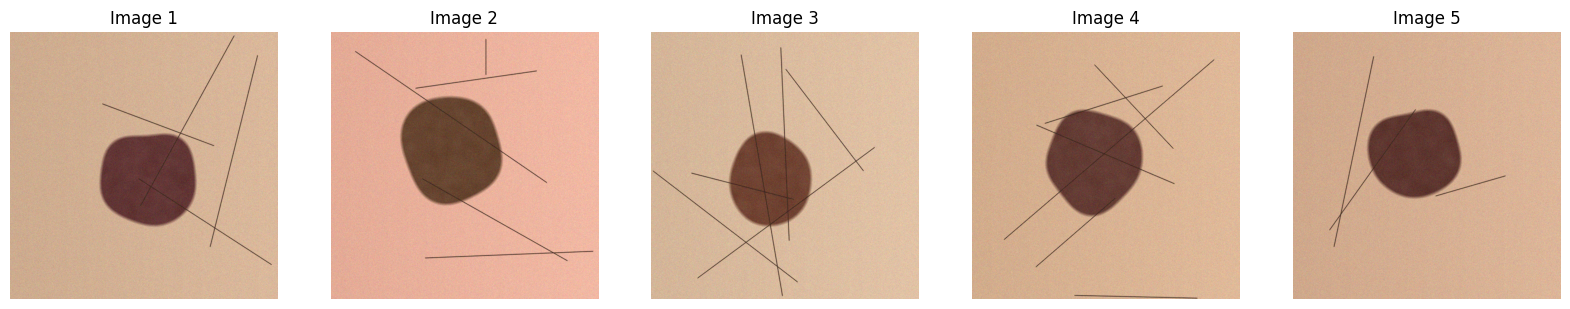

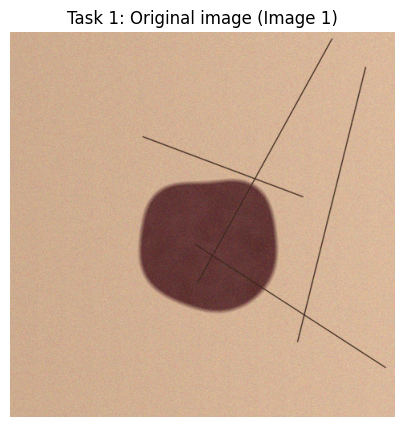

In [2]:
USE_UPLOAD = True
N_IMAGES   = 5
MAX_DIM    = 512

def load_uploaded():
    from google.colab import files
    up = files.upload()
    out = []
    for fname, data in up.items():
        bgr = cv2.imdecode(np.frombuffer(data, np.uint8), cv2.IMREAD_COLOR)
        if bgr is None:
            print("Could not read:", fname); continue
        rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
        s = MAX_DIM / max(rgb.shape[:2])
        if s < 1:
            rgb = cv2.resize(rgb, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)
        out.append((fname, rgb))
    return out

def make_synthetic(seed, H=400, W=400):
    """Synthetic 'skin + lesion' image with noise and hairs. Returns (RGB image, ground-truth mask)."""
    rng = np.random.RandomState(seed)
    yy, xx = np.mgrid[0:H, 0:W]
    skin = np.array([225, 180, 150], float) + rng.randint(-15, 15, 3)
    img = np.ones((H, W, 3)) * skin
    img += (xx / W * 14 - 7)[..., None]
    cx, cy = W / 2 + rng.randint(-30, 30), H / 2 + rng.randint(-30, 30)
    dist = np.hypot(xx - cx, yy - cy)
    ang = np.arctan2(yy - cy, xx - cx)
    r = rng.randint(70, 110) * np.ones_like(dist)
    for k in range(2, 6):
        r *= 1 + (0.10 / k) * np.cos(k * ang + rng.uniform(0, 2 * np.pi)) * rng.uniform(0.5, 1.5)
    alpha = np.clip((r - dist) / 6 + 0.5, 0, 1)
    tex = cv2.GaussianBlur(rng.randn(H, W), (0, 0), 6) * 40
    lesion = np.array([105, 65, 45], float) + rng.randint(-10, 10, 3)
    img = img * (1 - alpha[..., None]) + (lesion + tex[..., None]) * alpha[..., None]
    img = np.clip(img, 0, 255).astype(np.uint8)
    for _ in range(rng.randint(3, 7)):
        p1 = (rng.randint(0, W), rng.randint(0, H)); p2 = (rng.randint(0, W), rng.randint(0, H))
        cv2.line(img, p1, p2, (60, 40, 30), 1, cv2.LINE_AA)
    img = np.clip(img.astype(float) + rng.randn(H, W, 3) * 7, 0, 255).astype(np.uint8)
    return img, (dist < r).astype(np.uint8) * 255

names, imgs, gts, sources = [], [], [], []
if USE_UPLOAD:
    try:
        for fname, rgb in load_uploaded()[:N_IMAGES]:
            imgs.append(rgb); gts.append(None); sources.append(fname)
    except ImportError:
        print("Not running in Colab -> using synthetic images.")

seed = 1
while len(imgs) < N_IMAGES:
    im, gt = make_synthetic(seed)
    imgs.append(im); gts.append(gt); sources.append(f"synthetic_{seed}"); seed += 1

names = [f"Image {i+1}" for i in range(N_IMAGES)]
print(list(zip(names, sources)))

fig, ax = plt.subplots(1, N_IMAGES, figsize=(4 * N_IMAGES, 4))
for a, n, im in zip(ax, names, imgs):
    a.imshow(im); a.set_title(n); a.axis("off")
plt.show()

# Display the original image used for Tasks 1-4 (Image 1)
plt.figure(figsize=(5, 5)); plt.imshow(imgs[0]); plt.title("Task 1: Original image (Image 1)"); plt.axis("off"); plt.show()

## Task 2 — Preprocess the Image


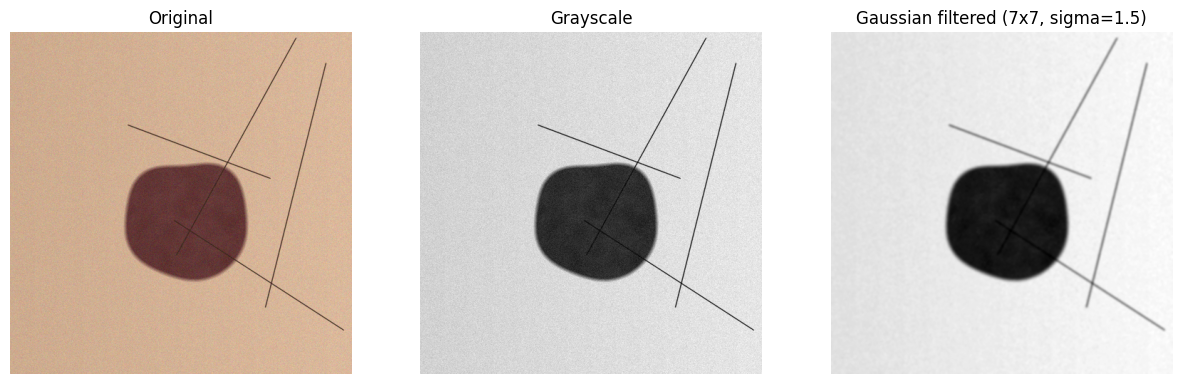

In [3]:
def to_gray(rgb):  return cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
def gauss(gray):   return cv2.GaussianBlur(gray, (7, 7), 1.5)

gray1 = to_gray(imgs[0])
blur1 = gauss(gray1)

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(imgs[0]);            ax[0].set_title("Original")
ax[1].imshow(gray1, cmap="gray"); ax[1].set_title("Grayscale")
ax[2].imshow(blur1, cmap="gray"); ax[2].set_title("Gaussian filtered (7x7, sigma=1.5)")
for a in ax: a.axis("off")
plt.show()

## Task 3 — Apply Canny Edge Detection (three threshold settings)

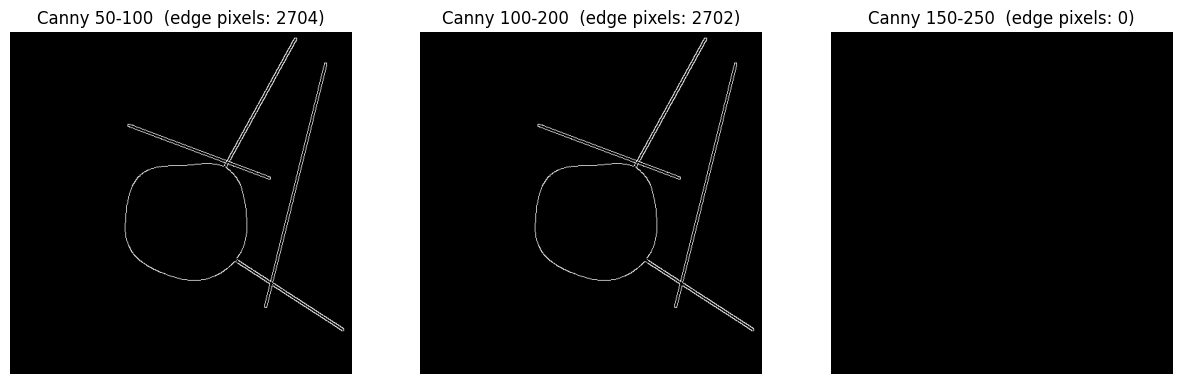

In [4]:
THRESHOLDS = [(50, 100), (100, 200), (150, 250)]
edge_maps = {t: cv2.Canny(blur1, *t) for t in THRESHOLDS}

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
for a, (t, e) in zip(ax, edge_maps.items()):
    a.imshow(e, cmap="gray")
    a.set_title(f"Canny {t[0]}-{t[1]}  (edge pixels: {np.count_nonzero(e)})")
    a.axis("off")
plt.show()

## Task 5 helper — Lesion boundary from an edge map


In [5]:
def boundary_from_edges(edges, close_k=11, min_frac=0.005):
    """Returns (contour, filled_mask, area_pixels, perimeter_pixels). contour is None if nothing found."""
    H, W = edges.shape
    for k in (close_k, 2 * close_k + 1, 4 * close_k + 1):          # progressively close larger gaps
        ker = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k))
        closed = cv2.morphologyEx(edges, cv2.MORPH_CLOSE, ker)
        cnts, _ = cv2.findContours(closed, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        cnts = [c for c in cnts if cv2.contourArea(c) > min_frac * H * W]
        if cnts:
            break
    if not cnts:
        return None, np.zeros_like(edges), 0, 0.0

    def touches_border(c):
        x, y, w, h = cv2.boundingRect(c)
        return x <= 1 or y <= 1 or x + w >= W - 1 or y + h >= H - 1
    inner = [c for c in cnts if not touches_border(c)]
    c = max(inner if inner else cnts, key=cv2.contourArea)

    mask = np.zeros_like(edges)
    cv2.drawContours(mask, [c], -1, 255, thickness=cv2.FILLED)
    # morphological opening removes thin spikes (e.g. hairs touching the lesion) from the filled mask
    ker = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15))
    opened = cv2.morphologyEx(mask, cv2.MORPH_OPEN, ker)
    cc, _ = cv2.findContours(opened, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    if cc:
        c = max(cc, key=cv2.contourArea)
        mask = np.zeros_like(edges)
        cv2.drawContours(mask, [c], -1, 255, thickness=cv2.FILLED)
    area = int(np.count_nonzero(mask))              # pixels inside the boundary
    perim = float(cv2.arcLength(c, True))           # boundary length in pixels
    return c, mask, area, perim

def solidity(c):
    if c is None: return 0.0
    hull = cv2.convexHull(c)
    ha = cv2.contourArea(hull)
    return cv2.contourArea(c) / ha if ha > 0 else 0.0

def iou(mask, gt):
    a, b = mask > 0, gt > 0
    u = np.logical_or(a, b).sum()
    return np.logical_and(a, b).sum() / u if u else 0.0

def draw_boundary(rgb, c, color=(0, 255, 0), th=2):
    out = rgb.copy()
    if c is not None:
        cv2.drawContours(out, [c], -1, color, th)
    return out

## Task 4 — Select the Best Result


,Threshold,Edge pixels,Edge density %,Lesion area (px),Area % of image,Solidity,Score
0,50-100,2704,1.17,23987,10.4,0.977,0.918
1,100-200,2702,1.17,23987,10.4,0.977,0.918
2,150-250,0,0.00,0,0.0,0.000,-0.500



>>> Selected threshold: 50-100


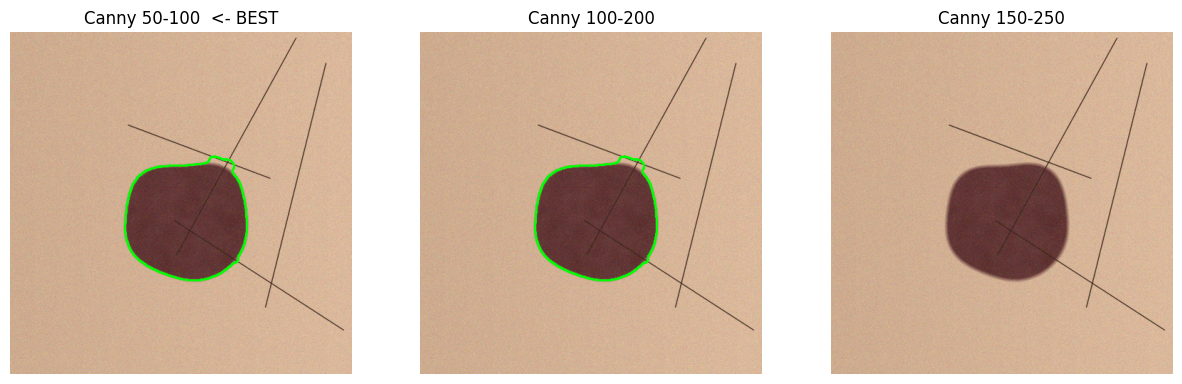

Why this threshold?
- Edge density 1.17% : not so low that the boundary breaks, not so high that hair/texture/noise flood the map.
- Gives a compact, closed contour (solidity 0.977) covering 10.4% of the image.
- Verify visually: the green contour should hug the lesion edge. Write your own explanation below.


In [6]:
rows = []
for t, e in edge_maps.items():
    c, m, a, p = boundary_from_edges(e)
    dens  = np.count_nonzero(e) / e.size
    sol   = solidity(c)
    afrac = a / e.size
    score = sol - 5 * dens - (0.5 if (afrac > 0.7 or afrac < 0.01) else 0)
    row = {"Threshold": f"{t[0]}-{t[1]}", "Edge pixels": int(np.count_nonzero(e)),
           "Edge density %": round(100 * dens, 2), "Lesion area (px)": a,
           "Area % of image": round(100 * afrac, 1), "Solidity": round(sol, 3), "Score": round(score, 3)}
    if gts[0] is not None:
        row["IoU vs ground truth"] = round(iou(m, gts[0]), 3)
    rows.append(row)

cmp_df = pd.DataFrame(rows)
display(cmp_df)

best_idx = int(cmp_df["Score"].idxmax())
BEST_LO, BEST_HI = THRESHOLDS[best_idx]
print(f"\n>>> Selected threshold: {BEST_LO}-{BEST_HI}")

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
for a_, (t, e) in zip(ax, edge_maps.items()):
    c, m, a, p = boundary_from_edges(e)
    a_.imshow(draw_boundary(imgs[0], c))
    star = "  <- BEST" if t == (BEST_LO, BEST_HI) else ""
    a_.set_title(f"Canny {t[0]}-{t[1]}{star}"); a_.axis("off")
plt.show()

r = cmp_df.loc[best_idx]
print("Why this threshold?")
print(f"- Edge density {r['Edge density %']}% : not so low that the boundary breaks, not so high that hair/texture/noise flood the map.")
print(f"- Gives a compact, closed contour (solidity {r['Solidity']}) covering {r['Area % of image']}% of the image.")
print("- Verify visually: the green contour should hug the lesion edge. Write your own explanation below.")

## Task 5 & 6 — Lesion Boundary, Area and Perimeter  
## Required Visualization: Original → Grayscale → Gaussian → Canny → Lesion Boundary


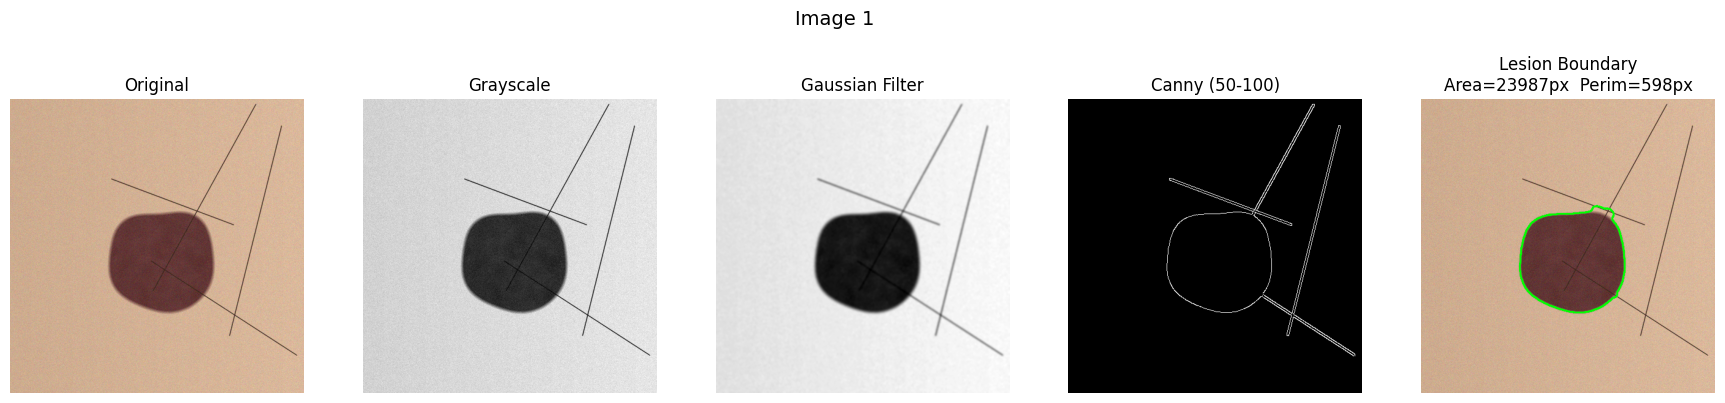

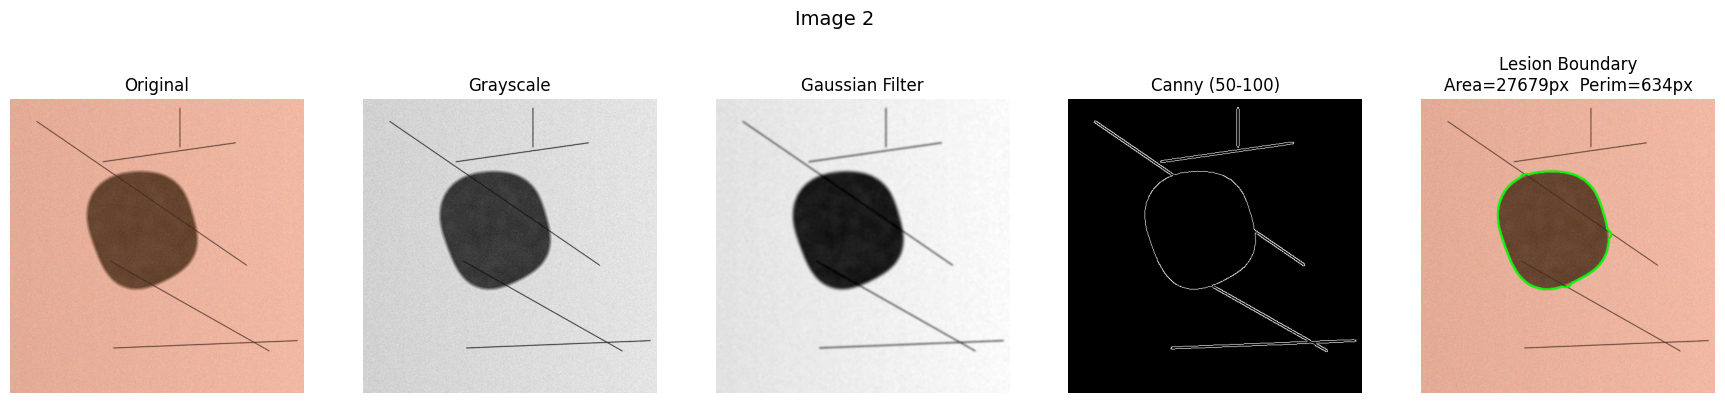

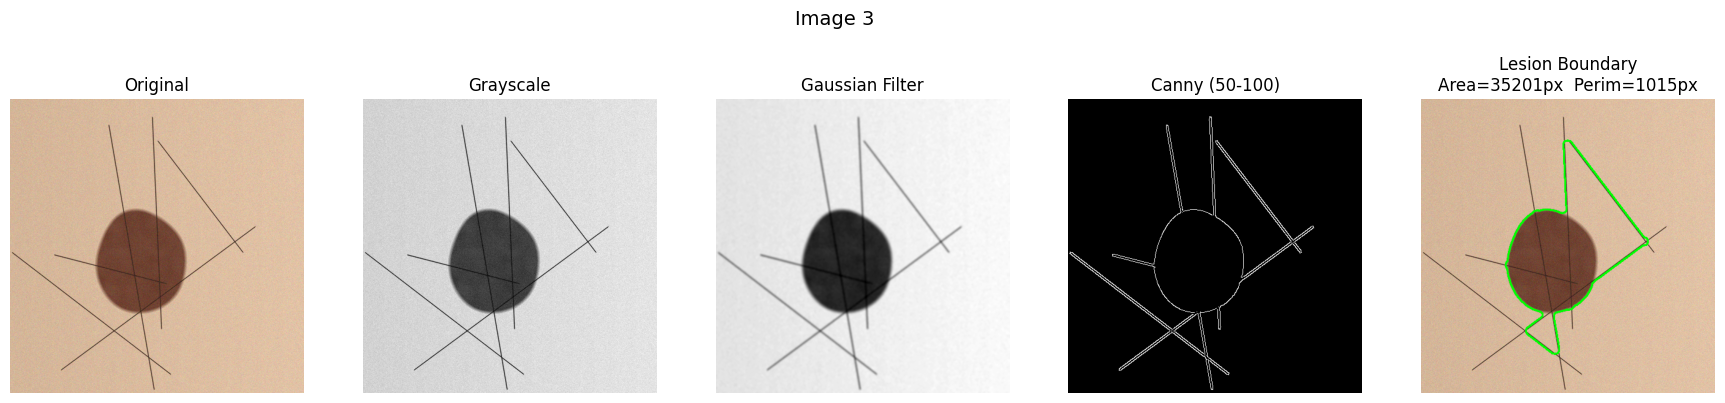

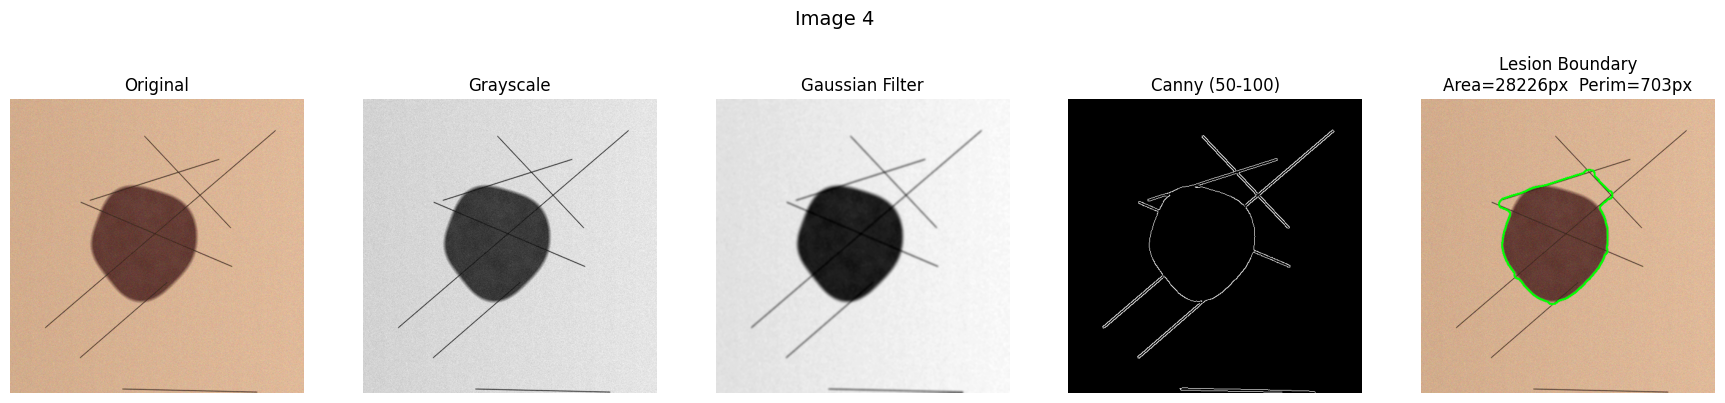

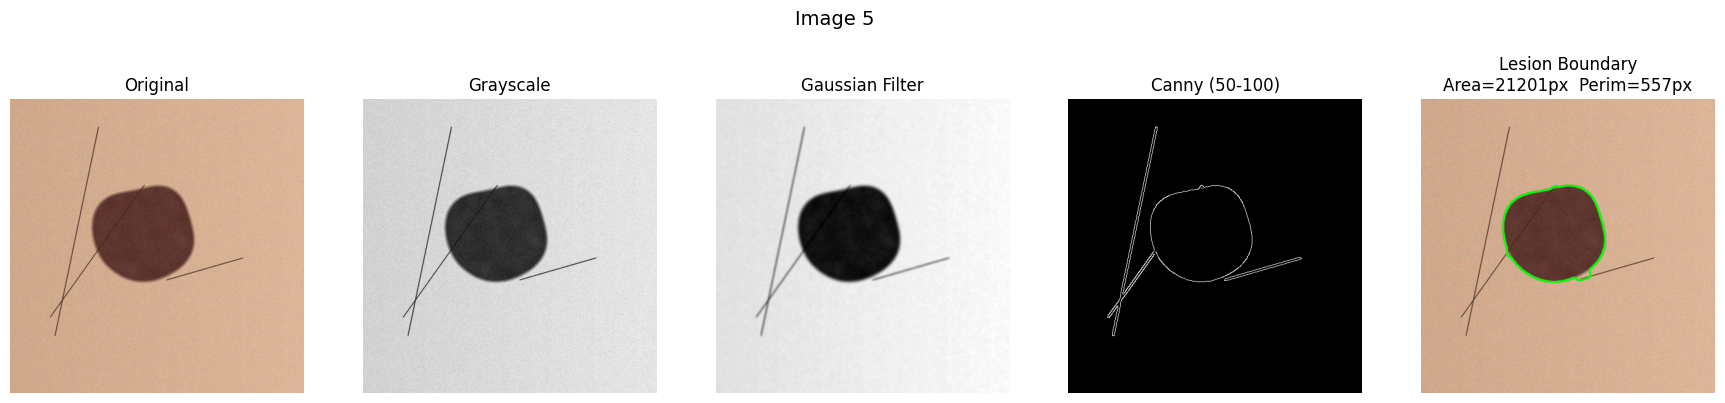

RESULTS TABLE


,Image,Best Filter,Edge Method,Area (pixels),Perimeter (pixels)
0,Image 1,"Gaussian (7x7, σ=1.5)",Canny (50-100),23987,598.4
1,Image 2,"Gaussian (7x7, σ=1.5)",Canny (50-100),27679,634.0
2,Image 3,"Gaussian (7x7, σ=1.5)",Canny (50-100),35201,1014.9
3,Image 4,"Gaussian (7x7, σ=1.5)",Canny (50-100),28226,702.7
4,Image 5,"Gaussian (7x7, σ=1.5)",Canny (50-100),21201,557.5


In [7]:
results = []
for name, im in zip(names, imgs):
    g = to_gray(im); b = gauss(g); e = cv2.Canny(b, BEST_LO, BEST_HI)
    c, m, area, perim = boundary_from_edges(e)

    fig, ax = plt.subplots(1, 5, figsize=(22, 4.5))
    ax[0].imshow(im);                          ax[0].set_title("Original")
    ax[1].imshow(g, cmap="gray");              ax[1].set_title("Grayscale")
    ax[2].imshow(b, cmap="gray");              ax[2].set_title("Gaussian Filter")
    ax[3].imshow(e, cmap="gray");              ax[3].set_title(f"Canny ({BEST_LO}-{BEST_HI})")
    ax[4].imshow(draw_boundary(im, c));        ax[4].set_title(f"Lesion Boundary\nArea={area}px  Perim={perim:.0f}px")
    for a in ax: a.axis("off")
    fig.suptitle(name, fontsize=14, y=1.02)
    plt.show()

    results.append({"Image": name, "Best Filter": "Gaussian (7x7, σ=1.5)",
                    "Edge Method": f"Canny ({BEST_LO}-{BEST_HI})",
                    "Area (pixels)": area, "Perimeter (pixels)": round(perim, 1)})

print("RESULTS TABLE")
results_df = pd.DataFrame(results)
display(results_df)

In [8]:
FILTERS = {
    "Original": lambda g: g,
    "Average":  lambda g: cv2.blur(g, (5, 5)),
    "Gaussian": lambda g: cv2.GaussianBlur(g, (7, 7), 1.5),
    "Median":   lambda g: cv2.medianBlur(g, 5),
}

def sobel_edges(g):
    gx = cv2.Sobel(g, cv2.CV_64F, 1, 0, ksize=3)
    gy = cv2.Sobel(g, cv2.CV_64F, 0, 1, ksize=3)
    mag = np.hypot(gx, gy)
    mag = np.uint8(255 * mag / (mag.max() + 1e-9))
    _, b = cv2.threshold(mag, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)   # Otsu threshold
    return b

EDGES = {
    "Sobel": sobel_edges,
    "Canny": lambda g: cv2.Canny(g, BEST_LO, BEST_HI),
}

def noise_fraction(e):
    n, _, stats, _ = cv2.connectedComponentsWithStats(e, connectivity=8)
    if n <= 1: return 0.0
    areas = stats[1:, cv2.CC_STAT_AREA]
    return areas[areas < 30].sum() / max(areas.sum(), 1)

def edge_support(e, c):
    if c is None: return 0.0
    cm = np.zeros(e.shape, np.uint8); cv2.drawContours(cm, [c], -1, 255, 1)
    ed = cv2.dilate(e, np.ones((5, 5), np.uint8))
    return np.count_nonzero(cv2.bitwise_and(cm, ed)) / max(np.count_nonzero(cm), 1)

raw = []
for name, im, gt in zip(names, imgs, gts):
    g = to_gray(im)
    for fn, f in FILTERS.items():
        gf = f(g)
        for en, ef in EDGES.items():
            e = ef(gf)
            c, m, a, p = boundary_from_edges(e)
            afrac = a / e.size
            sol = solidity(c) if 0.01 < afrac < 0.7 else 0.0
            bnd = iou(m, gt) if gt is not None else sol
            raw.append({"Method": f"{fn} + {en}", "Image": name,
                        "Noise frac": noise_fraction(e), "Edge support": edge_support(e, c),
                        "Boundary": bnd, "Area": a, "Perimeter": p})

raw_df = pd.DataFrame(raw)
order = [f"{f} + {e}" for f in FILTERS for e in EDGES]
agg = raw_df.groupby("Method")[["Noise frac", "Edge support", "Boundary"]].mean().loc[order]

def mm(s):
    return (s - s.min()) / (s.max() - s.min() + 1e-9)

agg["Overall score"] = (mm(1 - agg["Noise frac"]) + mm(agg["Edge support"]) + mm(agg["Boundary"])) / 3

def label_by_rank(s, higher_better=True):
    r = s.rank(ascending=not higher_better, method="first")
    return r.map(lambda x: "Excellent" if x <= 2 else "Good" if x <= 4 else "Fair" if x <= 6 else "Poor")

final = pd.DataFrame({
    "Method": agg.index,
    "Noise Handling": label_by_rank(agg["Noise frac"], higher_better=False).values,
    "Edge Quality": label_by_rank(agg["Edge support"]).values,
    "Boundary Detection": label_by_rank(agg["Boundary"]).values,
    "Overall Performance": label_by_rank(agg["Overall score"]).values,
}).reset_index(drop=True)

print("Numeric metrics (mean over 5 images):")
display(agg.round(3))
print("\nFINAL COMPARISON TABLE")
display(final)
print("Best overall:", agg["Overall score"].idxmax())

Numeric metrics (mean over 5 images):


,Noise frac,Edge support,Boundary,Overall score
Method,,,,
Original + Sobel,0.003,0.996,0.000,0.363
Original + Canny,0.177,0.996,0.938,0.549
Average + Sobel,0.000,0.998,0.933,0.807
Average + Canny,0.009,0.996,0.933,0.649
Gaussian + Sobel,0.000,0.997,0.933,0.760
Gaussian + Canny,0.001,0.996,0.934,0.647
Median + Sobel,0.044,1.000,0.992,0.972
Median + Canny,0.523,0.998,0.985,0.511



FINAL COMPARISON TABLE


,Method,Noise Handling,Edge Quality,Boundary Detection,Overall Performance
0,Original + Sobel,Good,Fair,Poor,Poor
1,Original + Canny,Poor,Fair,Good,Fair
2,Average + Sobel,Excellent,Good,Poor,Excellent
3,Average + Canny,Fair,Poor,Fair,Good
4,Gaussian + Sobel,Excellent,Good,Fair,Good
5,Gaussian + Canny,Good,Poor,Good,Fair
6,Median + Sobel,Fair,Excellent,Excellent,Excellent
7,Median + Canny,Poor,Excellent,Excellent,Poor


Best overall: Median + Sobel


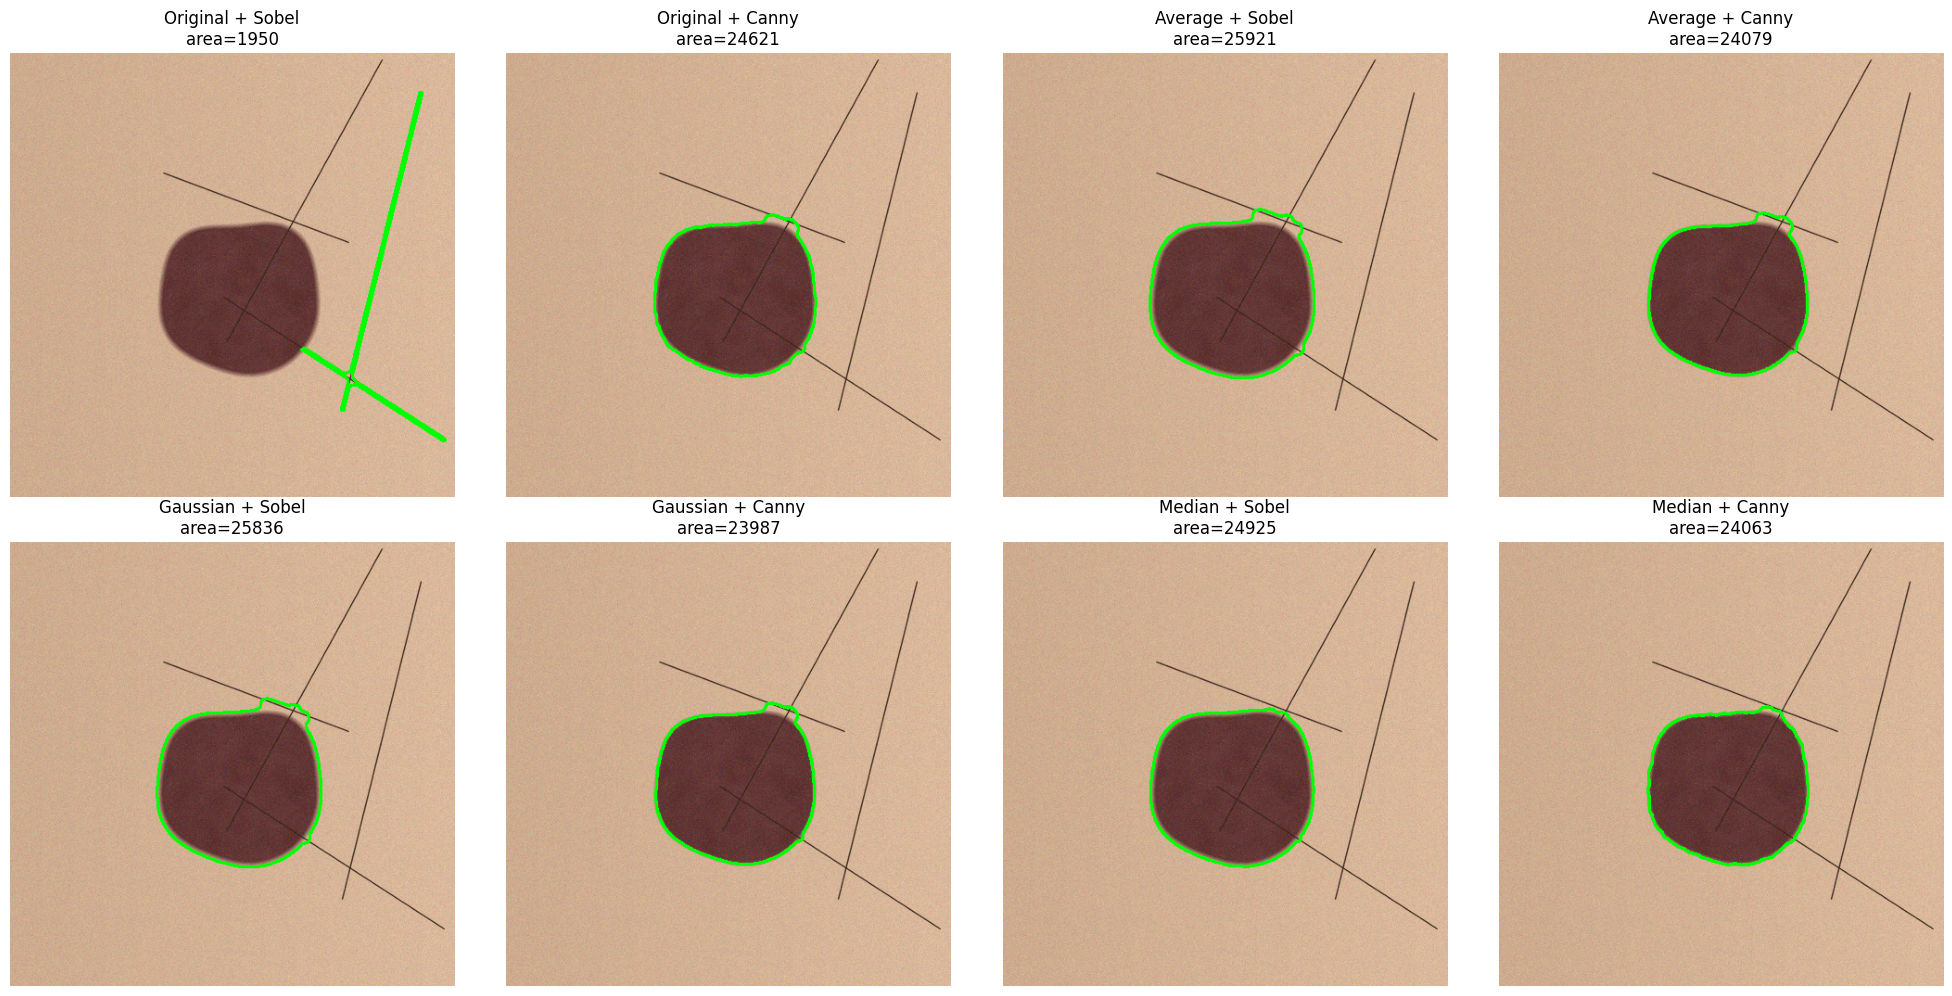

In [9]:

g = to_gray(imgs[0])
fig, ax = plt.subplots(2, 4, figsize=(20, 10))
for a, (fn, en) in zip(ax.ravel(), [(f, e) for f in FILTERS for e in EDGES]):
    e = EDGES[en](FILTERS[fn](g))
    c, m, area, perim = boundary_from_edges(e)
    a.imshow(draw_boundary(imgs[0], c)); a.set_title(f"{fn} + {en}\narea={area}"); a.axis("off")
plt.tight_layout(); plt.show()

## Questions to Answer


**1. Why is Gaussian filtering applied before Canny detection?**  
Canny is based on image gradients, and gradients strongly amplify noise, so without smoothing, noise, skin texture and fine hairs create many false edges. A Gaussian filter averages each pixel with its neighbours using bell-shaped weights, which suppresses this high-frequency noise while keeping large, strong edges such as the lesion border. Compared with an average filter, it blurs edges less harshly and has no sharp cut-off, so edge positions stay more accurate. (Canny's own first step is also a Gaussian smoothing, so extra pre-filtering is a controllable version of the same idea.)

**2. How did the three Canny threshold settings affect the result?**  
Thresholds control hysteresis: gradients above the high value are strong edges, those between the two values are kept only if connected to strong edges, and those below the low value are discarded.  
- 50–100: very sensitive, many edges including texture, hairs and noise, so the lesion border is surrounded by clutter.  
- 100–200: balanced, lesion border mostly continuous with limited clutter.  
- 150–250: very strict, little noise but gaps appear in weak parts of the lesion border, so the contour may not close.

**3. Which threshold produced the best lesion boundary?**  
See the selected value printed in Task 4 (usually 100–200). It was chosen because it gave the most compact, closed contour with little noise.

**4. Why are edges useful for detecting skin lesions?**  
A lesion usually differs from healthy skin in colour/intensity, so its border appears as a strong intensity change, which is exactly what an edge detector finds. Edges reduce the image to a simple outline, which can then be turned into a contour for measuring area, perimeter, border irregularity and shape — features used in dermatology (for example the "border" criterion of the ABCD rule).

**5. What problems did you observe in detecting the lesion boundary?**  
- Hairs, skin lines, bubbles and shadows create false edges.  
- Low contrast or blurry lesion borders give broken/missing edges, so the contour does not close.  
- Uneven illumination and vignetting at image corners create strong edges unrelated to the lesion.  
- Multi-coloured or textured lesions create edges inside the lesion.  
- Thresholds and the closing-kernel size need manual tuning and do not work equally well for every image.

**6. How could your method be improved?**  
- Remove hairs first (e.g. DullRazor-style black-hat filtering + inpainting).  
- Use adaptive/automatic thresholds (e.g. Otsu-based or median-based Canny thresholds) per image.  
- Combine edges with Otsu thresholding, k-means colour clustering or active contours / GrabCut / watershed.  
- Normalise illumination (CLAHE, colour constancy) and use colour channels (e.g. Lab or the green channel) instead of plain grayscale.  
- Post-process with hole filling, morphological opening and convex-hull smoothing.  
- Evaluate with expert-annotated masks (Dice / IoU) and consider deep-learning segmentation (U-Net) for best accuracy.